In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

sys.path.append("../..")
from src.data.dataset_utils import exclude_boundary_nodes
from src.utils.plot_functions import plot_overall_scores, plot_binned_scores, plot_spatial_grids, spatial_grid_from_dataarray

VARIABLE = "sigWaveHeight"  # significant wave height

PREDICT_FINAL_DIR = Path("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_final")
GROUND_TRUTH_ZARR = "/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr"
BOUNDARY_NODES_CSV = "../../src/data/node_selection/boundary_nodes.csv"

# produced by notebooks/paper-plots/compute_experiment_metrics.py
METRICS_DIR = Path("metrics")

CHUNKS = "auto"  # keep everything dask-backed/lazy; set to None to load eagerly

In [ ]:
PAPER_WIDE = (7.1, 3.5)

In [ ]:
def parse_bin_column(bin_series: pd.Series) -> pd.Series:
    """Turn the 'bin' column of a binned-metrics CSV back into pd.Interval objects.

    compute_binned_scores/compute_binned_change_scores return 'bin' as a pd.Interval
    (or the string 'overall'), which round-trips through CSV as a plain string like
    '(0.0, 0.5]'. plot_binned_scores expects real pd.Interval objects (for .mid), so
    we parse them back here after loading the CSV.
    """

    def _parse(value):
        if value == "overall":
            return value
        left, right = value.strip("()[]").split(", ")
        return pd.Interval(float(left), float(right), closed="right")

    return bin_series.apply(_parse)

## RMSE

### Global

In [ ]:
summary_df = pd.read_csv(METRICS_DIR / "summary_metrics.csv")
summary_df.round(decimals=4)

,experiment,total_rmse,total_bias,summer_rmse,summer_bias,winter_rmse,winter_bias
0,swh-gat-500,0.0559,0.0109,0.0349,-0.0083,0.0714,0.0309
1,swh-gat-lstm-vn-48-50,0.0210,0.0005,0.0174,-0.0030,0.0242,0.0041
2,swh-gat-lstm-vn-48-500,0.0249,-0.0004,0.0188,-0.0051,0.0299,0.0045
3,swh-gat-lstm-vn-6-50,0.0220,-0.0010,0.0176,-0.0040,0.0258,0.0021
4,swh-gat-lstm-vn-6-500,0.0247,0.0004,0.0182,-0.0035,0.0300,0.0044
5,swh-gat-vn-50,0.0472,0.0102,0.0333,-0.0039,0.0581,0.0247
6,swh-gat-vn-500,0.0429,-0.0006,0.0321,-0.0104,0.0518,0.0095
7,swh-lstm-48,0.0189,-0.0007,0.0169,-0.0019,0.0208,0.0006
8,swh-lstm-6,0.0208,0.0018,0.0180,0.0012,0.0234,0.0024
9,swh-mlp,0.0502,0.0009,0.0412,-0.0146,0.0581,0.0170


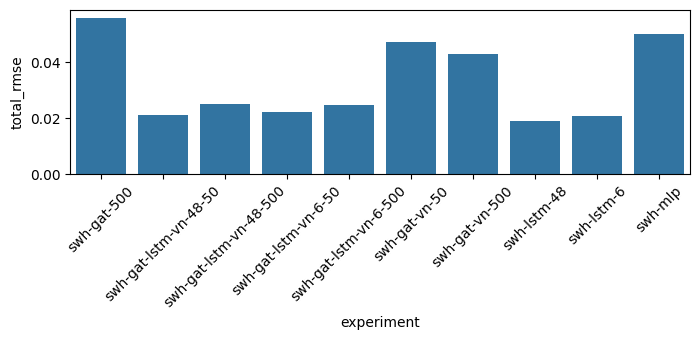

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=summary_df, x="experiment", y="total_rmse", ax=ax)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Summer

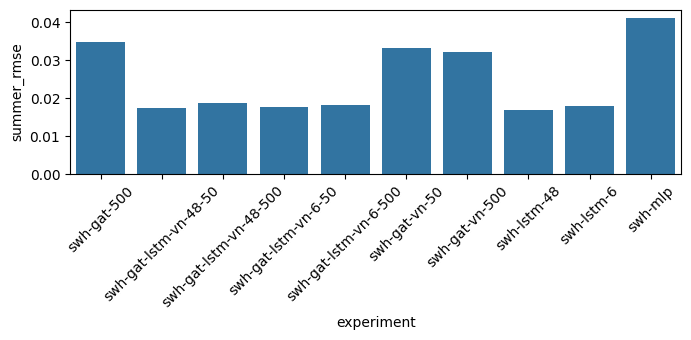

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=summary_df, x="experiment", y="summer_rmse", ax=ax)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Winter

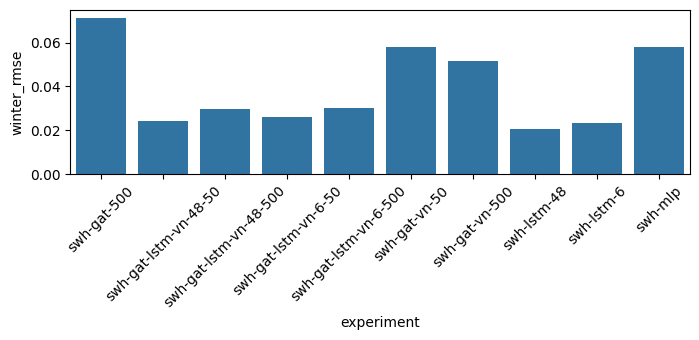

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=summary_df, x="experiment", y="winter_rmse", ax=ax)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Bias

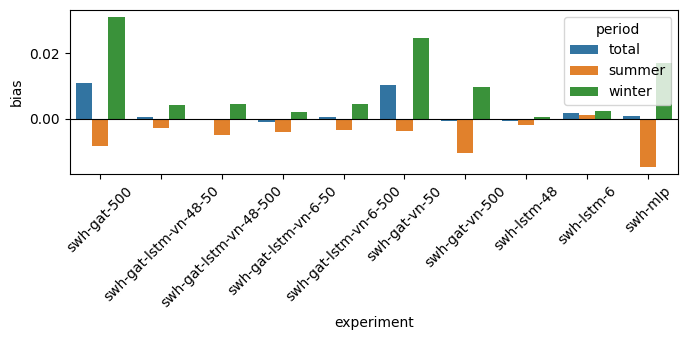

In [ ]:
bias_df = summary_df.melt(
    id_vars="experiment",
    value_vars=["total_bias", "summer_bias", "winter_bias"],
    var_name="period",
    value_name="bias",
)
bias_df["period"] = bias_df["period"].str.replace("_bias", "")

fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=bias_df, x="experiment", y="bias", hue="period", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Binned by value

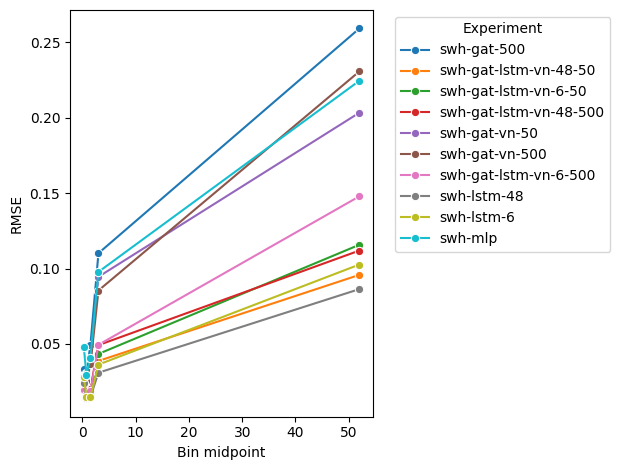

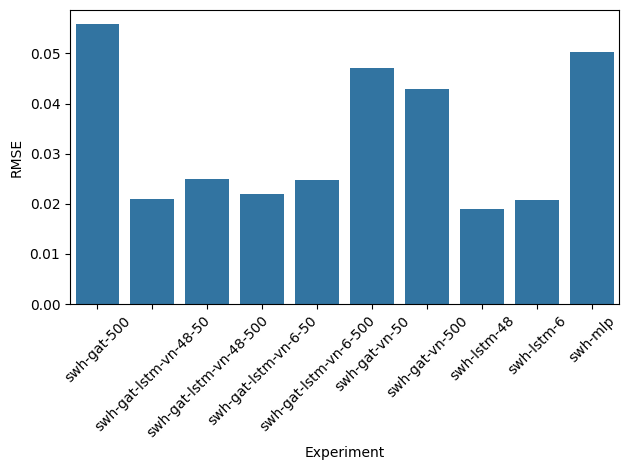

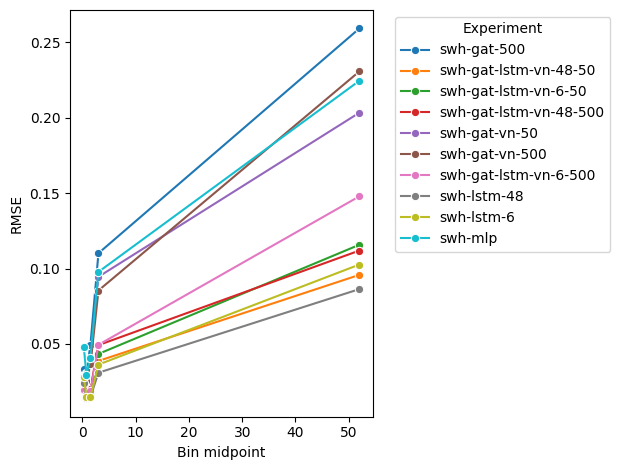

In [ ]:
binned_value_df = pd.read_csv(METRICS_DIR / "binned_value_metrics.csv")
binned_value_df["bin"] = parse_bin_column(binned_value_df["bin"])

plot_overall_scores(binned_value_df, metric="rmse")
plot_binned_scores(binned_value_df, metric="rmse")

### Binned by change

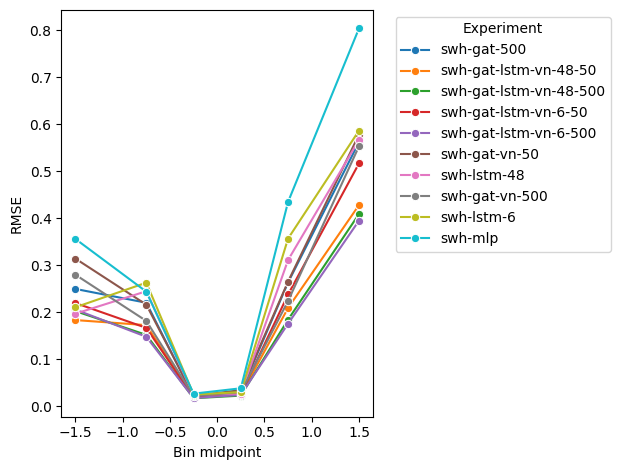

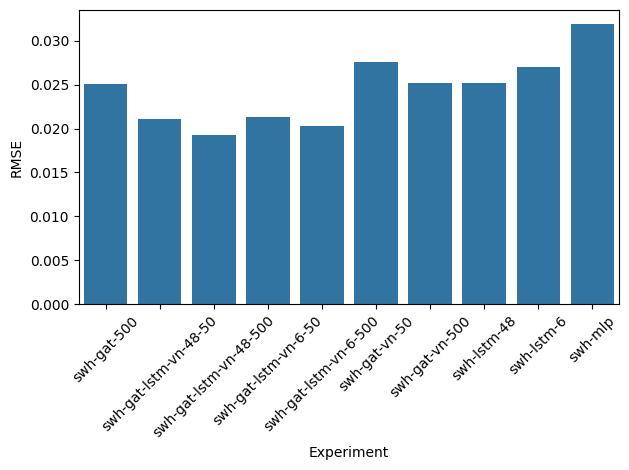

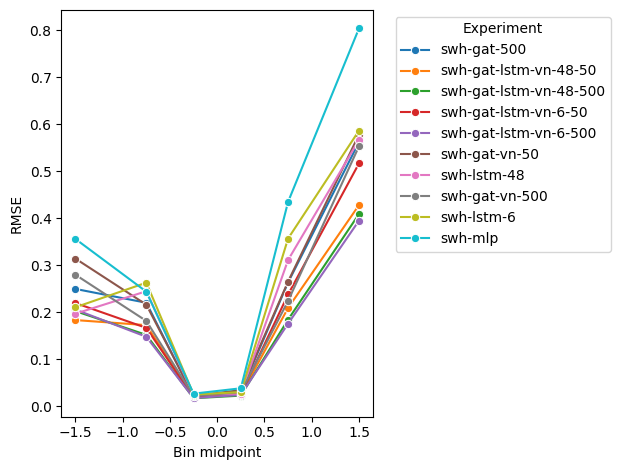

In [ ]:
binned_change_df = pd.read_csv(METRICS_DIR / "binned_change_metrics.csv")
binned_change_df["bin"] = parse_bin_column(binned_change_df["bin"])

plot_overall_scores(binned_change_df, metric="rmse")
plot_binned_scores(binned_change_df, metric="rmse")

## Selected experiments only

In [ ]:
keep_experiments = ["swh-mlp", "swh-lstm-6", "swh-lstm-48", "swh-gat-500", "swh-gat-vn-500", "swh-gat-lstm-vn-6-50", "swh-gat-lstm-vn-6-500", "swh-gat-lstm-vn-48-500"]

In [ ]:
# define architecture priority for sorting
arch_priority = {
    "mlp": 0,
    "lstm": 1,
    "gat": 2,        # Graph (must check before gat-vn / gat-lstm-vn, see note below)
    "gat-vn": 3,      # Graph-VN
    "gat-lstm-vn": 4, # Graph-LSTM
}

def get_arch_key(experiment):
    # order matters: check longest/most-specific patterns first
    if "gat-lstm-vn" in experiment:
        return arch_priority["gat-lstm-vn"]
    if "gat-vn" in experiment:
        return arch_priority["gat-vn"]
    if "gat" in experiment:
        return arch_priority["gat"]
    if "lstm" in experiment:
        return arch_priority["lstm"]
    if "mlp" in experiment:
        return arch_priority["mlp"]
    return 99  # fallback, shouldn't hit if keep_experiments is well-formed

hue_order = sorted(keep_experiments, key=get_arch_key)

new_labels = ["MLP", "LSTM (sl=6)", "LSTM (sl=48)", "Graph (w/o VN) (n=500)", "Graph (n=500)", "GraphLSTM (sl=6, n=50)", "GraphLSTM (sl=6, n=500)", "GraphLSTM (sl=48, n=500)"]

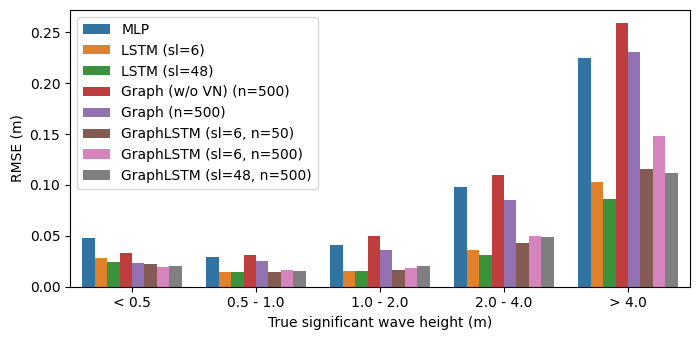

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_value_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="rmse", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True significant wave height (m)")
ax.set_ylabel("RMSE (m)")

ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(["< 0.5", "0.5 - 1.0", "1.0 - 2.0", "2.0 - 4.0", "> 4.0"])

handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("rmse_swh_per_swh_bin.png", dpi=200)

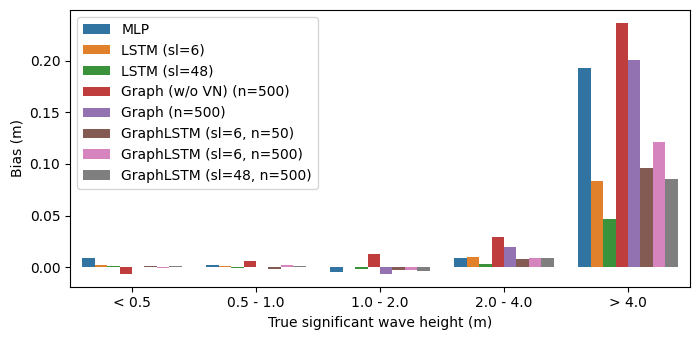

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_value_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="bias", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True significant wave height (m)")
ax.set_ylabel("Bias (m)")

ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(["< 0.5", "0.5 - 1.0", "1.0 - 2.0", "2.0 - 4.0", "> 4.0"])

handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("bias_swh_per_swh_bin.png", dpi=200)

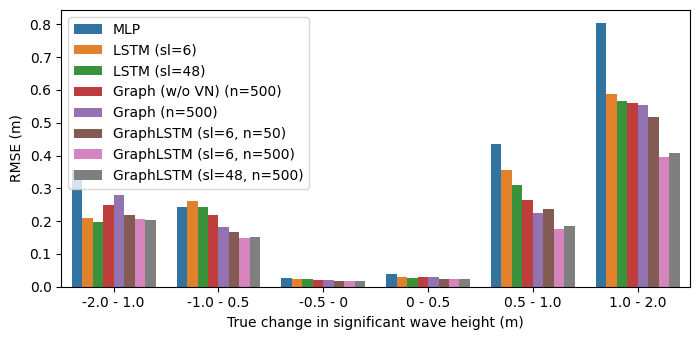

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_change_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="rmse", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True change in significant wave height (m)")
ax.set_ylabel("RMSE (m)")

ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.set_xticklabels(["-2.0 - 1.0", "-1.0 - 0.5", "-0.5 - 0", "0 - 0.5", "0.5 - 1.0", "1.0 - 2.0"])


handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("rmse_swh_per_dswh_bin.png", dpi=200)

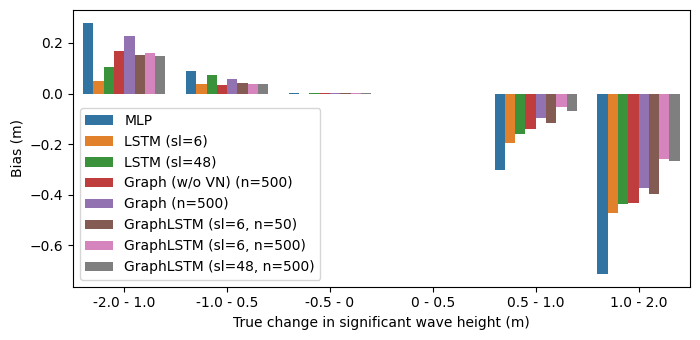

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_change_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="bias", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True change in significant wave height (m)")
ax.set_ylabel("Bias (m)")

ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.set_xticklabels(["-2.0 - 1.0", "-1.0 - 0.5", "-0.5 - 0", "0 - 0.5", "0.5 - 1.0", "1.0 - 2.0"])


handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("bias_swh_per_dswh_bin.png", dpi=200)

## Spatial analysis

In [ ]:
skeys = ["mlp", "lstm-6"]#, "gat-vn-50", "gat-lstm-vn-6-50"]
sdict = {}

for key in skeys:
    print(key)
    sdict[key] = xr.open_dataset(f"./spatial_metrics/swh-{key}_spatial_metrics.nc")

mlp
lstm-6


FileNotFoundError: [Errno 2] No such file or directory: '/work/ka1176/caroline/gitlab/wave-wind-model-emulator/notebooks/paper-plots/spatial_metrics/swh-lstm-6_spatial_metrics.nc'

In [ ]:
grids = {key: spatial_grid_from_dataarray(sdict[key].sel(season="winter")["rmse"]) for key in skeys}

In [ ]:
fig = plot_spatial_grids({"MLP":grids["mlp"]}, title="", cbar_label="RMSE (m)", vmin=0, vmax=0.225)

In [ ]:
# ground truth maps: swap "rmse" for "ground_truth_mean" and use a different cmap/vmin/vmax
gt_grids = {
    "summer": spatial_grid_from_dataarray(sdict["mlp"]["ground_truth_mean"].sel(season="summer")),
    "winter": spatial_grid_from_dataarray(sdict["mlp"]["ground_truth_mean"].sel(season="winter")),
}
fig2 = plot_spatial_grids(gt_grids, title="sigWaveHeight (ground truth)", cbar_label="sigWaveHeight (m)", cmap="viridis")

## Rollout

In [ ]:
import glob

In [ ]:
all_frames = pd.concat([pd.read_csv(f) for f in glob.glob("../../logs/rollout/swh-mlp/rollout_metrics_lead_from_*.csv")])

In [ ]:
all_frames

In [ ]:
sns.lineplot(data=all_frames, x="lead", y="rmse_sigWaveHeight")